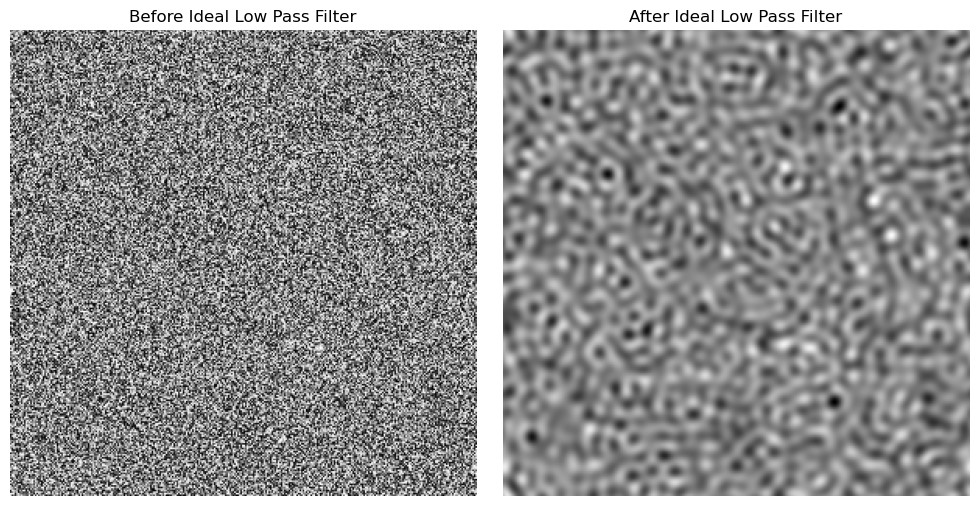

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Create a random image
img = np.random.randint(0, 256, (300, 300), dtype=np.uint8)

# Apply Fourier Transform
dft = np.fft.fft2(img)
dft_shift = np.fft.fftshift(dft)

# Create Ideal Low Pass Filter
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2
D0 = 30

mask = np.zeros((rows, cols), np.uint8)

for i in range(rows):
    for j in range(cols):
        D = np.sqrt((i-crow)**2 + (j-ccol)**2)
        if D <= D0:
            mask[i, j] = 1

# Apply filter
filtered = dft_shift * mask

# Inverse Fourier Transform
img_back = np.fft.ifft2(np.fft.ifftshift(filtered))
img_back = np.abs(img_back)

# Display images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Before Ideal Low Pass Filter")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_back, cmap='gray')
plt.title("After Ideal Low Pass Filter")
plt.axis('off')

plt.tight_layout()
plt.show()